# 03 · Análisis espacial y segmentación de cantones

Dos preguntas:

1. **¿El delito se agrupa en el territorio?** Si los cantones vecinos tienen tasas parecidas, la criminalidad de los vecinos es información útil para predecir la de cada cantón.
2. **¿Qué perfiles delictivos existen?** Agrupar los cantones según su combinación de delitos permite entender que no todos requieren el mismo tipo de intervención.

Se usa la tasa media anual 2023–2025 por 100.000 habitantes.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

from src import espacial, oij, viz

viz.estilo()
FIG = RAIZ / 'reports' / 'figures'
EXT = RAIZ / 'data' / 'external'
DELITOS = oij.DELITOS
ET = viz.ETIQUETAS_DELITO

In [2]:
anual = pd.read_parquet(RAIZ / 'data' / 'processed' / 'tasas_canton_anio.parquet')
rec = anual[anual['Anio'].between(2023, 2025)]
suma = rec.groupby(['Canton', 'Delito'])[['Delitos', 'Poblacion']].sum()
tasa = (suma['Delitos'] / suma['Poblacion'] * 1e5).unstack()[DELITOS]
pob3 = rec.drop_duplicates(['Canton', 'Anio']).groupby('Canton')['Poblacion'].sum()
tasa['TOTAL'] = rec.groupby('Canton')['Delitos'].sum() / pob3 * 1e5

geo = viz.cargar_geometrias(EXT / 'cantones.geojson')
tasa.describe().round(1)

Delito,HURTO,ASALTO,ROBO,ROBO DE VEHICULO,TACHA DE VEHICULO,HOMICIDIO,TOTAL
count,81.0,81.0,81.0,81.0,81.0,81.0,81.0
mean,224.5,144.6,174.3,84.4,69.0,17.1,713.8
std,182.0,134.6,96.8,44.1,130.5,20.8,475.7
min,63.2,15.9,52.3,14.5,0.0,0.0,245.7
25%,112.5,69.9,99.7,57.6,18.7,6.3,449.5
50%,159.3,109.5,156.8,75.6,37.4,11.3,562.0
75%,242.3,187.5,215.3,102.0,73.9,18.8,823.7
max,1054.7,1014.9,594.3,214.5,1107.5,121.2,2918.7


## 1. Quién es vecino de quién

Dos cantones son vecinos si sus límites se tocan (contigüidad tipo *reina*). Con esta matriz se calcula el **rezago espacial**: el promedio de una variable en los cantones vecinos.

In [3]:
W = espacial.matriz_vecindad(geo)
n_vecinos = W.sum(axis=1)
print(f'Vecinos por cantón: mínimo {n_vecinos.min()}, máximo {n_vecinos.max()}, media {n_vecinos.mean():.1f}')
print('Cantón con más vecinos:', n_vecinos.idxmax().title())

aristas = [(a, b) for a in W.index for b in W.columns if a < b and W.loc[a, b]]
pd.DataFrame(aristas, columns=['Canton', 'Vecino']).to_csv(EXT / 'vecindad_cantonal.csv', index=False)
print(f'{len(aristas)} pares de cantones vecinos guardados')

Vecinos por cantón: mínimo 2, máximo 14, media 5.3
Cantón con más vecinos: Heredia
214 pares de cantones vecinos guardados


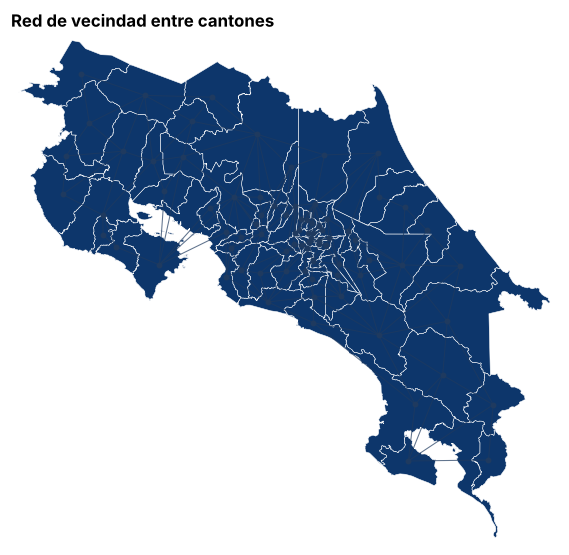

In [4]:
centros = {c: g.representative_point() for c, g in geo.items()}
fig, ax = plt.subplots(figsize=(6.5, 6))
viz.mapa(ax, geo, pd.Series(1, index=list(geo)), cortes=[0, 2], leyenda=False)
for a, b in aristas:
    ax.plot([centros[a].x, centros[b].x], [centros[a].y, centros[b].y], color=viz.AZUL, lw=0.7, alpha=0.7)
ax.scatter([p.x for p in centros.values()], [p.y for p in centros.values()], s=8, color=viz.AZUL, zorder=3)
ax.set_title('Red de vecindad entre cantones')
fig.savefig(FIG / '03_red_vecindad.png')

## 2. ¿El delito se agrupa? I de Moran global

El I de Moran mide si los cantones vecinos se parecen más de lo que cabría esperar por azar. Vale 0 aproximadamente si la distribución es aleatoria y es positivo si hay agrupamiento. La significancia se obtiene permutando las tasas entre cantones 999 veces. Se usa el logaritmo de la tasa para que los valores extremos (Garabito) no dominen el resultado.

In [5]:
moran = pd.DataFrame({
    ET.get(c, 'Total'): espacial.moran_global(np.log1p(tasa[c]), W) for c in DELITOS + ['TOTAL']
}).T.round(3)
moran

,I,esperado,p_valor
Hurto,0.203,-0.012,0.002
Asalto,0.286,-0.012,0.001
Robo,0.507,-0.012,0.001
Robo de vehículo,0.290,-0.012,0.001
Tacha de vehículo,0.199,-0.012,0.002
Homicidio,0.188,-0.012,0.006
Total,0.228,-0.012,0.003


**Lectura:** todos los delitos muestran **agrupamiento espacial significativo** (p < 0,01). El más fuerte es el robo (I = 0,51): las zonas con muchos robos forman regiones continuas. **Implicación para el modelo:** la tasa de los cantones vecinos es una variable explicativa justificada.

## 3. ¿Dónde están los focos? Moran local (LISA)

El Moran local clasifica cada cantón según su tasa y la de sus vecinos:

- **Alto-Alto:** foco, un cantón con tasa alta rodeado de cantones con tasa alta.
- **Bajo-Bajo:** zona fría.
- **Alto-Bajo / Bajo-Alto:** cantones atípicos respecto a su entorno.

Solo se colorean los cantones con p < 0,05. Con 81 pruebas simultáneas cabe esperar unos 4 falsos positivos, así que los resultados se interpretan como indicios, no como certezas.

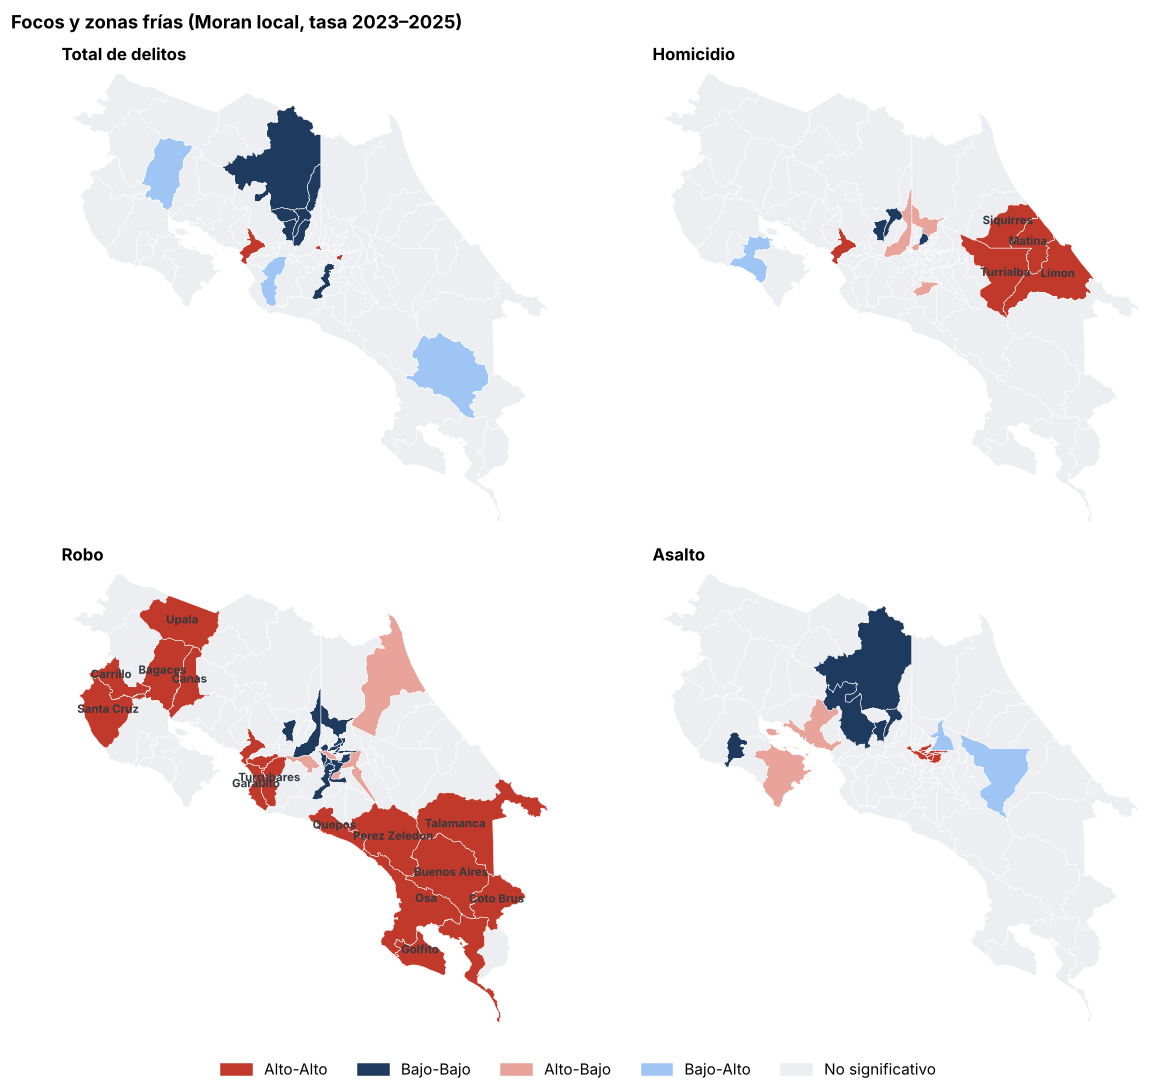

In [6]:
COLORES_LISA = {'Alto-Alto': '#c0392b', 'Bajo-Bajo': '#1f3a5f', 'Alto-Bajo': '#e8a39b',
                'Bajo-Alto': '#9ec5f4', 'No significativo': '#eceef1'}
lisa = {c: espacial.moran_local(np.log1p(tasa[c]), W) for c in ['TOTAL', 'HOMICIDIO', 'ROBO', 'ASALTO']}

fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for ax, (c, res) in zip(axes.flat, lisa.items()):
    for canton, g in geo.items():
        for p in (g.geoms if g.geom_type == 'MultiPolygon' else [g]):
            x, y = p.exterior.xy
            ax.fill(x, y, color=COLORES_LISA[res.loc[canton, 'tipo']], ec='white', lw=0.35)
    for canton in res.index[res['tipo'] == 'Alto-Alto']:
        if geo[canton].area < 0.02:  # los cantones metropolitanos son demasiado pequeños para rotularlos
            continue
        pt = geo[canton].representative_point()
        ax.annotate(canton.title(), (pt.x, pt.y), fontsize=7.5, ha='center', color='#33393f', fontweight='bold')
    ax.set_xlim(-86, -82.5); ax.set_ylim(8, 11.25); ax.set_aspect('equal'); ax.axis('off')
    ax.set_title(ET.get(c, 'Total de delitos'))
fig.legend(handles=[Patch(color=v, label=k) for k, v in COLORES_LISA.items()], loc='lower center', ncol=5)
fig.suptitle('Focos y zonas frías (Moran local, tasa 2023–2025)', x=0.01, ha='left', fontweight='bold')
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(FIG / '03_lisa_focos.png')

In [7]:
pd.DataFrame({ET.get(c, 'Total'): r['tipo'].value_counts() for c, r in lisa.items()}).fillna(0).astype(int)

,Total,Homicidio,Robo,Asalto
tipo,,,,
Alto-Alto,3,5,16,8
Alto-Bajo,0,3,4,1
Bajo-Alto,3,1,0,2
Bajo-Bajo,6,3,12,5
No significativo,69,69,49,65


In [8]:
{ET.get(c, 'Total'): sorted(r.index[r['tipo'] == 'Alto-Alto'].str.title()) for c, r in lisa.items()}

{'Total': ['Belen', 'Curridabat', 'Esparza'],
 'Homicidio': ['Esparza', 'Limon', 'Matina', 'Siquirres', 'Turrialba'],
 'Robo': ['Bagaces',
  'Buenos Aires',
  'Canas',
  'Carrillo',
  'Coto Brus',
  'Esparza',
  'Garabito',
  'Golfito',
  'Orotina',
  'Osa',
  'Perez Zeledon',
  'Quepos',
  'Santa Cruz',
  'Talamanca',
  'Turrubares',
  'Upala'],
 'Asalto': ['Belen',
  'Curridabat',
  'Goicoechea',
  'La Union',
  'Montes De Oca',
  'San Jose',
  'Santo Domingo',
  'Tibas']}

**Lectura:** cada delito tiene su propia geografía de focos:

- **Homicidio:** foco en el **Caribe** (Limón, Matina, Siquirres) que se extiende hacia Turrialba.
- **Robo:** el foco más extenso, en la **periferia rural y costera**: Guanacaste (Santa Cruz, Carrillo, Cañas, Bagaces), el Pacífico Central (Garabito, Quepos, Orotina) y la zona sur (Osa, Golfito, Coto Brus, Buenos Aires, Pérez Zeledón).
- **Asalto:** foco en el **centro del área metropolitana** (San José, Montes de Oca, Curridabat, Goicoechea, Tibás, Santo Domingo, La Unión, Belén); en el mapa no se rotulan porque son cantones muy pequeños.

Las zonas frías se concentran en cantones rurales del occidente del Valle Central. **Implicación:** los recursos para prevenir homicidios, robos y asaltos deberían orientarse a regiones distintas.

## 4. Perfiles delictivos de los cantones

Cada cantón se describe con sus seis tasas (en logaritmo y estandarizadas, para que todos los delitos pesen igual). Se agrupan con **k-means**, que reúne los cantones con perfiles parecidos.

,silueta,inercia
k,,
2,0.311,313.411
3,0.243,253.883
4,0.230,214.392
5,0.211,192.568
6,0.197,176.570
7,0.186,160.632


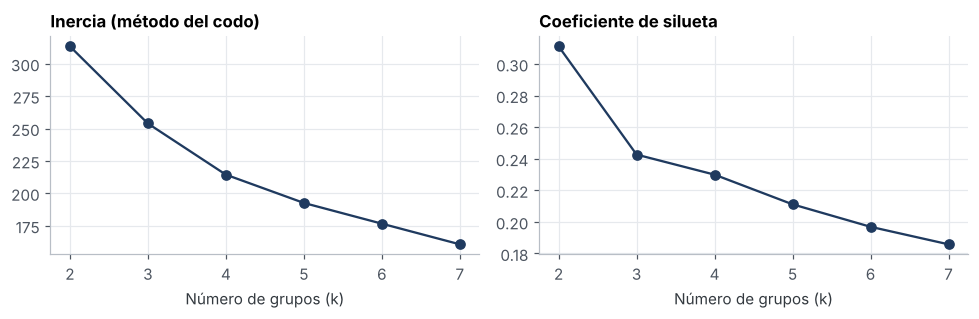

In [9]:
X = StandardScaler().fit_transform(np.log1p(tasa[DELITOS]))
pruebas = []
for k in range(2, 8):
    km = KMeans(k, n_init=50, random_state=0).fit(X)
    pruebas.append({'k': k, 'silueta': silhouette_score(X, km.labels_), 'inercia': km.inertia_})
pruebas = pd.DataFrame(pruebas).set_index('k')

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].plot(pruebas.index, pruebas['inercia'], marker='o'); axes[0].set_title('Inercia (método del codo)')
axes[1].plot(pruebas.index, pruebas['silueta'], marker='o'); axes[1].set_title('Coeficiente de silueta')
for ax in axes: ax.set_xlabel('Número de grupos (k)')
fig.tight_layout()
pruebas.round(3)

La silueta es moderada en todos los casos (0,2–0,3): los cantones forman un continuo más que grupos totalmente separados, algo habitual con datos sociales. Se elige **k = 4**: su silueta es casi igual a la de k = 3 y da grupos más fáciles de interpretar y de usar para decidir intervenciones.

In [10]:
km = KMeans(4, n_init=50, random_state=0).fit(X)
grupo = pd.Series(km.labels_, index=tasa.index)
# Ordenar los grupos de mayor a menor tasa total para que los números sean estables
orden = tasa['TOTAL'].groupby(grupo).median().sort_values(ascending=False).index
grupo = grupo.map({g: i for i, g in enumerate(orden)})
perfil = tasa.groupby(grupo).median().round(0)
perfil['Cantones'] = grupo.value_counts().sort_index()
perfil

Delito,HURTO,ASALTO,ROBO,ROBO DE VEHICULO,TACHA DE VEHICULO,HOMICIDIO,TOTAL,Cantones
0,388.0,268.0,280.0,143.0,133.0,30.0,1288.0,17
1,214.0,96.0,206.0,63.0,25.0,15.0,620.0,20
2,125.0,125.0,99.0,79.0,47.0,8.0,510.0,28
3,95.0,36.0,148.0,37.0,18.0,5.0,334.0,16


In [11]:
NOMBRES = {
    0: 'Alta criminalidad: urbanos y turísticos',
    1: 'Rural y periférico con robo y hurto',
    2: 'Urbano residencial del Valle Central',
    3: 'Rural de baja criminalidad',
}
for g, n in NOMBRES.items():
    print(f'{g}. {n} ({(grupo == g).sum()}):', ', '.join(sorted(grupo.index[grupo == g].str.title())))

0. Alta criminalidad: urbanos y turísticos (17): Alajuela, Cartago, Garabito, Heredia, Liberia, Limon, Matina, Montes De Oca, Nicoya, Orotina, Osa, Parrita, Puntarenas, Quepos, San Jose, Santa Cruz, Talamanca
1. Rural y periférico con robo y hurto (20): Abangares, Bagaces, Buenos Aires, Canas, Carrillo, Corredores, Coto Brus, Golfito, Guatuso, La Cruz, Los Chiles, Perez Zeledon, Pococi, Puriscal, San Carlos, San Mateo, San Ramon, Siquirres, Turrialba, Upala
2. Urbano residencial del Valle Central (28): Alajuelita, Aserri, Atenas, Barva, Belen, Curridabat, Desamparados, El Guarco, Escazu, Esparza, Flores, Goicoechea, Grecia, Guacimo, La Union, Montes De Oro, Moravia, Oreamuno, Paraiso, San Isidro, San Pablo, San Rafael, Santa Ana, Santa Barbara, Santo Domingo, Sarapiqui, Tibas, Vasquez De Coronado
3. Rural de baja criminalidad (16): Acosta, Alvarado, Dota, Hojancha, Jimenez, Leon Cortes, Mora, Nandayure, Naranjo, Palmares, Poas, Sarchi, Tarrazu, Tilaran, Turrubares, Zarcero


Los nombres se asignaron a partir de la tabla de perfiles y de la lista de cantones de cada grupo; conviene revisarlos al leer los resultados.

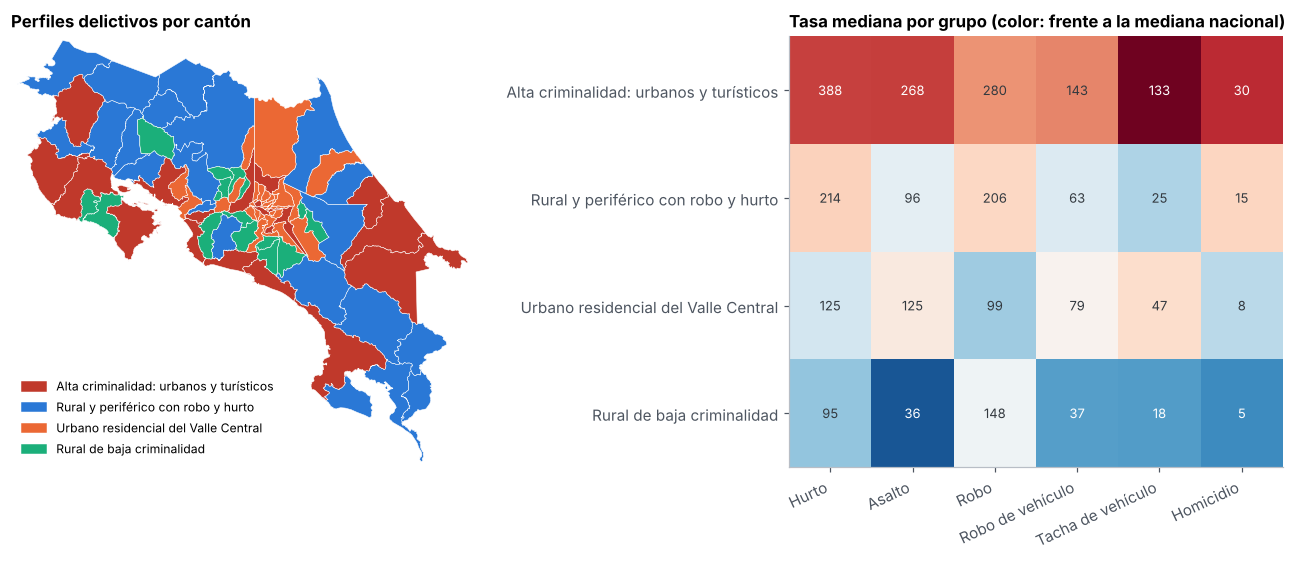

In [12]:
COLORES_GRUPO = {0: '#c0392b', 1: '#2a78d6', 2: '#eb6834', 3: '#1baf7a'}
fig = plt.figure(figsize=(12, 5.2))
ax1 = fig.add_subplot(1, 2, 1)
for canton, g in geo.items():
    for p in (g.geoms if g.geom_type == 'MultiPolygon' else [g]):
        x, y = p.exterior.xy
        ax1.fill(x, y, color=COLORES_GRUPO[grupo[canton]], ec='white', lw=0.35)
ax1.set_xlim(-86, -82.5); ax1.set_ylim(8, 11.25); ax1.set_aspect('equal'); ax1.axis('off')
ax1.set_title('Perfiles delictivos por cantón')
ax1.legend(handles=[Patch(color=COLORES_GRUPO[g], label=n) for g, n in NOMBRES.items()], loc='lower left', fontsize=8)

ax2 = fig.add_subplot(1, 2, 2)
rel = np.log(perfil[DELITOS] / tasa[DELITOS].median())
im = ax2.imshow(rel.values, cmap='RdBu_r', vmin=-1.3, vmax=1.3, aspect='auto')
ax2.set_xticks(range(len(DELITOS)), [ET[d] for d in DELITOS], rotation=25, ha='right')
ax2.set_yticks(range(4), [NOMBRES[g] for g in perfil.index]); ax2.grid(False)
for (i, j), v in np.ndenumerate(perfil[DELITOS].values):
    ax2.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=8.5, color='white' if abs(rel.values[i, j]) > 0.7 else '#33393f')
ax2.set_title('Tasa mediana por grupo (color: frente a la mediana nacional)')
fig.tight_layout()
fig.savefig(FIG / '03_perfiles_cantones.png')

,Hurto,Asalto,Robo,Robo de vehículo,Tacha de vehículo,Homicidio
PC1,0.46,0.47,0.31,0.41,0.41,0.37
PC2,0.35,-0.35,0.74,-0.40,-0.20,0.06


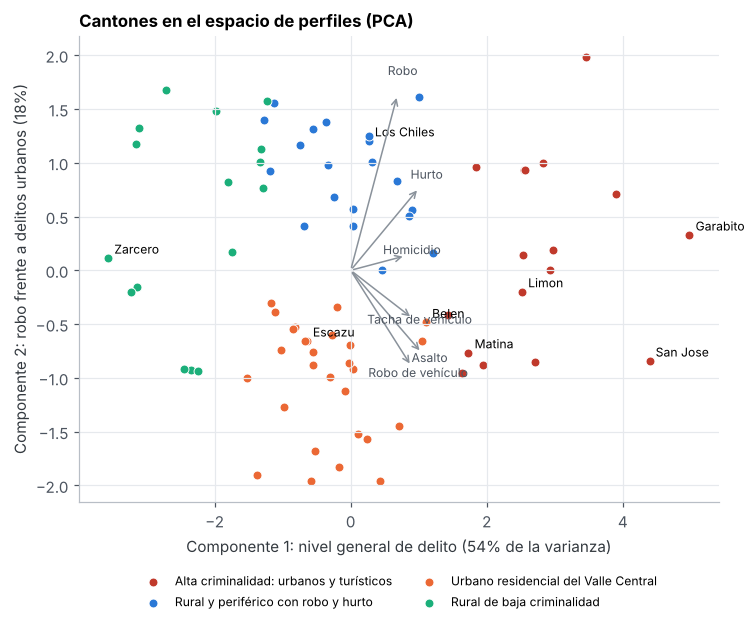

In [13]:
pca = PCA(2).fit(X)
Z = pca.transform(X)
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for g, n in NOMBRES.items():
    m = (grupo == g).values
    ax.scatter(Z[m, 0], Z[m, 1], s=34, color=COLORES_GRUPO[g], label=n, edgecolor='white', lw=0.6)
for c in ['SAN JOSE', 'GARABITO', 'LIMON', 'ESCAZU', 'ZARCERO', 'LOS CHILES', 'MATINA', 'BELEN']:
    i = tasa.index.get_loc(c)
    ax.annotate(c.title(), (Z[i, 0], Z[i, 1]), xytext=(4, 3), textcoords='offset points', fontsize=8)
for j, d in enumerate(DELITOS):
    ax.annotate('', xy=pca.components_[:, j] * 2.2, xytext=(0, 0), arrowprops=dict(arrowstyle='->', color=viz.GRIS))
    ax.text(*(pca.components_[:, j] * 2.45), ET[d], fontsize=8, color='#4d5560', ha='center')
v = pca.explained_variance_ratio_
ax.set_xlabel(f'Componente 1: nivel general de delito ({v[0]:.0%} de la varianza)')
ax.set_ylabel(f'Componente 2: robo frente a delitos urbanos ({v[1]:.0%})')
ax.legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=2); ax.set_title('Cantones en el espacio de perfiles (PCA)')
fig.savefig(FIG / '03_pca_perfiles.png')
pd.DataFrame(pca.components_, columns=[ET[d] for d in DELITOS], index=['PC1', 'PC2']).round(2)

**Lectura:**

- **El primer componente (54 % de la varianza) es el nivel general de delito:** todas las tasas pesan en la misma dirección. Los cantones que tienen mucho de un delito suelen tener mucho de todos.
- **El segundo componente separa dos tipos de criminalidad:** el robo y el hurto, más rurales, frente al asalto y los delitos contra vehículos, más urbanos.
- **Implicación práctica:** los grupos sugieren intervenciones distintas. En los cantones urbanos residenciales del Valle Central pesan el asalto y los delitos contra vehículos; en los rurales y periféricos, el robo y el hurto.
- **Implicación para el modelo:** el grupo de cada cantón puede usarse como variable, y también para evaluar si el modelo acierta igual de bien en todos los tipos de cantón.

## 5. Guardar

In [14]:
salida = pd.DataFrame({
    'Grupo': grupo, 'Grupo_nombre': grupo.map(NOMBRES),
    'LISA_total': lisa['TOTAL']['tipo'], 'LISA_homicidio': lisa['HOMICIDIO']['tipo'],
    'Vecinos': n_vecinos,
})
salida.index.name = 'Canton'
salida.to_csv(RAIZ / 'data' / 'processed' / 'perfil_cantones.csv')
salida.head()

,Grupo,Grupo_nombre,LISA_total,LISA_homicidio,Vecinos
Canton,,,,,
ABANGARES,1,Rural y periférico con robo y hurto,No significativo,No significativo,3
ACOSTA,3,Rural de baja criminalidad,No significativo,No significativo,6
ALAJUELA,0,Alta criminalidad: urbanos y turísticos,No significativo,Alto-Bajo,10
ALAJUELITA,2,Urbano residencial del Valle Central,No significativo,No significativo,6
ALVARADO,3,Rural de baja criminalidad,No significativo,No significativo,4


## 6. Conclusiones

1. **El delito está agrupado en el territorio** para los seis tipos (I de Moran significativo). La tasa de los cantones vecinos entrará como variable en el modelo.
2. **Hay focos identificables**, distintos para cada tipo de delito, como el foco de homicidios del Caribe.
3. **Los cantones se organizan en cuatro perfiles:** alta criminalidad (centros urbanos y destinos turísticos), rural y periférico con robo y hurto, urbano residencial del Valle Central y rural de baja criminalidad.
4. Se guardan la vecindad entre cantones (`data/external/vecindad_cantonal.csv`) y el perfil de cada cantón (`data/processed/perfil_cantones.csv`) para los siguientes notebooks.